In [2]:
# ==============================================================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

# ==============================================================================
# 2. CARREGAMENTO E INSPEÇÃO INICIAL
# ==============================================================================
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Dimensões iniciais (linhas, colunas):", df.shape)
print("\nTipos de dados iniciais:")
print(df.info())

Dimensões iniciais (linhas, colunas): (7043, 21)

Tipos de dados iniciais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract      

In [3]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [4]:
# ==============================================================================
# 3. VALIDAÇÃO E TRATAMENTO DOS DADOS
# ==============================================================================
# 3.1 Validar IDs duplicados e remover coluna identificadora
print("\nIDs duplicados:", df["customerID"].duplicated().sum())
df = df.drop(columns=["customerID"])

# 3.2 Remover espaços em branco extras nas colunas de texto
colunas_texto = df.select_dtypes(include="object").columns
for col in colunas_texto:
    df[col] = df[col].str.strip()

# 3.3 Corrigir tipo de dado (TotalCharges veio como texto por ter espaços vazios)
print("\nNulos ANTES de converter TotalCharges:", df.isnull().sum().sum())
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# 3.4 Validar e tratar valores nulos
print("\nValores nulos por coluna (após conversão):")
print(df.isnull().sum()[df.isnull().sum() > 0])

df = df.dropna()

# 3.5 Validar e tratar linhas duplicadas
duplicadas = df.duplicated().sum()
print(f"\nLinhas duplicadas encontradas: {duplicadas}")
if duplicadas > 0:
    df = df.drop_duplicates()

# Reorganiza o índice após as remoções
df = df.reset_index(drop=True)

# 3.6 Validar consistência das variáveis numéricas (checar negativos/outliers)
print("\nResumo estatístico das colunas numéricas:")
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2))

# 3.7 Validar categorias únicas nas colunas de texto (checar erros de digitação)
print("\nCategorias únicas por coluna de texto:")
for col in df.select_dtypes(include="object").columns:
    print(f"- {col}: {df[col].unique()}")

# 3.8 Checklist final da limpeza
print("\n===== VALIDAÇÃO FINAL DA BASE =====")
print("Dimensões após tratamento:", df.shape)
print("Total de nulos restantes :", df.isnull().sum().sum())
print("Total de duplicadas      :", df.duplicated().sum())



IDs duplicados: 0

Nulos ANTES de converter TotalCharges: 0

Valores nulos por coluna (após conversão):
TotalCharges    11
dtype: int64

Linhas duplicadas encontradas: 22

Resumo estatístico das colunas numéricas:
        tenure  MonthlyCharges  TotalCharges
count  7010.00         7010.00       7010.00
mean     32.52           64.89       2290.35
std      24.52           30.06       2266.82
min       1.00           18.25         18.80
25%       9.00           35.75        408.31
50%      29.00           70.40       1403.88
75%      56.00           89.90       3807.84
max      72.00          118.75       8684.80

Categorias únicas por coluna de texto:
- gender: ['Female' 'Male']
- Partner: ['Yes' 'No']
- Dependents: ['No' 'Yes']
- PhoneService: ['No' 'Yes']
- MultipleLines: ['No phone service' 'No' 'Yes']
- InternetService: ['DSL' 'Fiber optic' 'No']
- OnlineSecurity: ['No' 'Yes' 'No internet service']
- OnlineBackup: ['Yes' 'No' 'No internet service']
- DeviceProtection: ['No' 'Yes' '


Contagem das classes:
Churn
No     5153
Yes    1857
Name: count, dtype: int64

Proporção das classes (%):
Churn
No     73.51
Yes    26.49
Name: proportion, dtype: float64


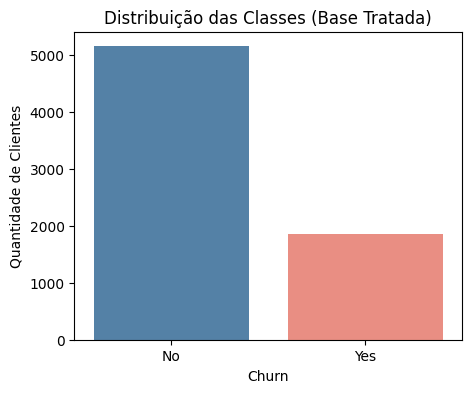

In [5]:
# ==============================================================================
# 4. VERIFICAÇÃO DO BALANCEAMENTO DA BASE
# ==============================================================================
print("\nContagem das classes:")
print(df["Churn"].value_counts())

print("\nProporção das classes (%):")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(5, 4))
sns.countplot(x="Churn", hue="Churn", data=df, palette=["steelblue", "salmon"], legend=False)
plt.title("Distribuição das Classes (Base Tratada)")
plt.ylabel("Quantidade de Clientes")
plt.show()

In [6]:
# ==============================================================================
# 5. PRÉ-PROCESSAMENTO (GET_DUMMIES + SPLIT)
# ==============================================================================
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

In [7]:
# ==============================================================================
# 6. BALANCEAMENTO COM SMOTE (APENAS NO TREINO)
# ==============================================================================
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("\nTreino ANTES do SMOTE:")
print(y_train.value_counts())

print("\nTreino DEPOIS do SMOTE:")
print(y_train_smote.value_counts())


Treino ANTES do SMOTE:
Churn
0    3607
1    1300
Name: count, dtype: int64

Treino DEPOIS do SMOTE:
Churn
0    3607
1    3607
Name: count, dtype: int64



===== RESULTADOS - KNN (COM SMOTE) =====
Acurácia: 0.7461

              precision    recall  f1-score   support

   Não Churn       0.88      0.76      0.81      1546
       Churn       0.51      0.71      0.60       557

    accuracy                           0.75      2103
   macro avg       0.70      0.74      0.71      2103
weighted avg       0.78      0.75      0.76      2103



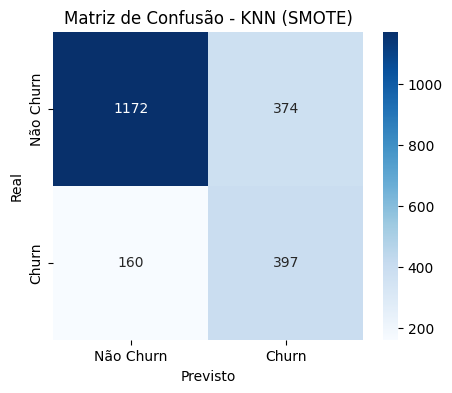

In [8]:
# ==============================================================================
# 7. MODELO 1: KNN
# ==============================================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=11)
knn.fit(X_train_scaled, y_train_smote)

y_pred_knn = knn.predict(X_test_scaled)

print("\n===== RESULTADOS - KNN (COM SMOTE) =====")
print(f"Acurácia: {accuracy_score(y_test, y_pred_knn):.4f}\n")
print(classification_report(y_test, y_pred_knn, target_names=["Não Churn", "Churn"]))

plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_knn),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Não Churn", "Churn"],
    yticklabels=["Não Churn", "Churn"]
)
plt.title("Matriz de Confusão - KNN (SMOTE)")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.show()




===== RESULTADOS - ÁRVORE DE DECISÃO (COM SMOTE) =====
Acurácia: 0.7066

              precision    recall  f1-score   support

   Não Churn       0.88      0.70      0.78      1546
       Churn       0.47      0.73      0.57       557

    accuracy                           0.71      2103
   macro avg       0.67      0.72      0.67      2103
weighted avg       0.77      0.71      0.72      2103



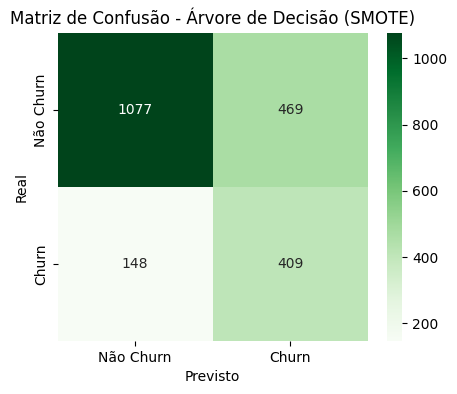

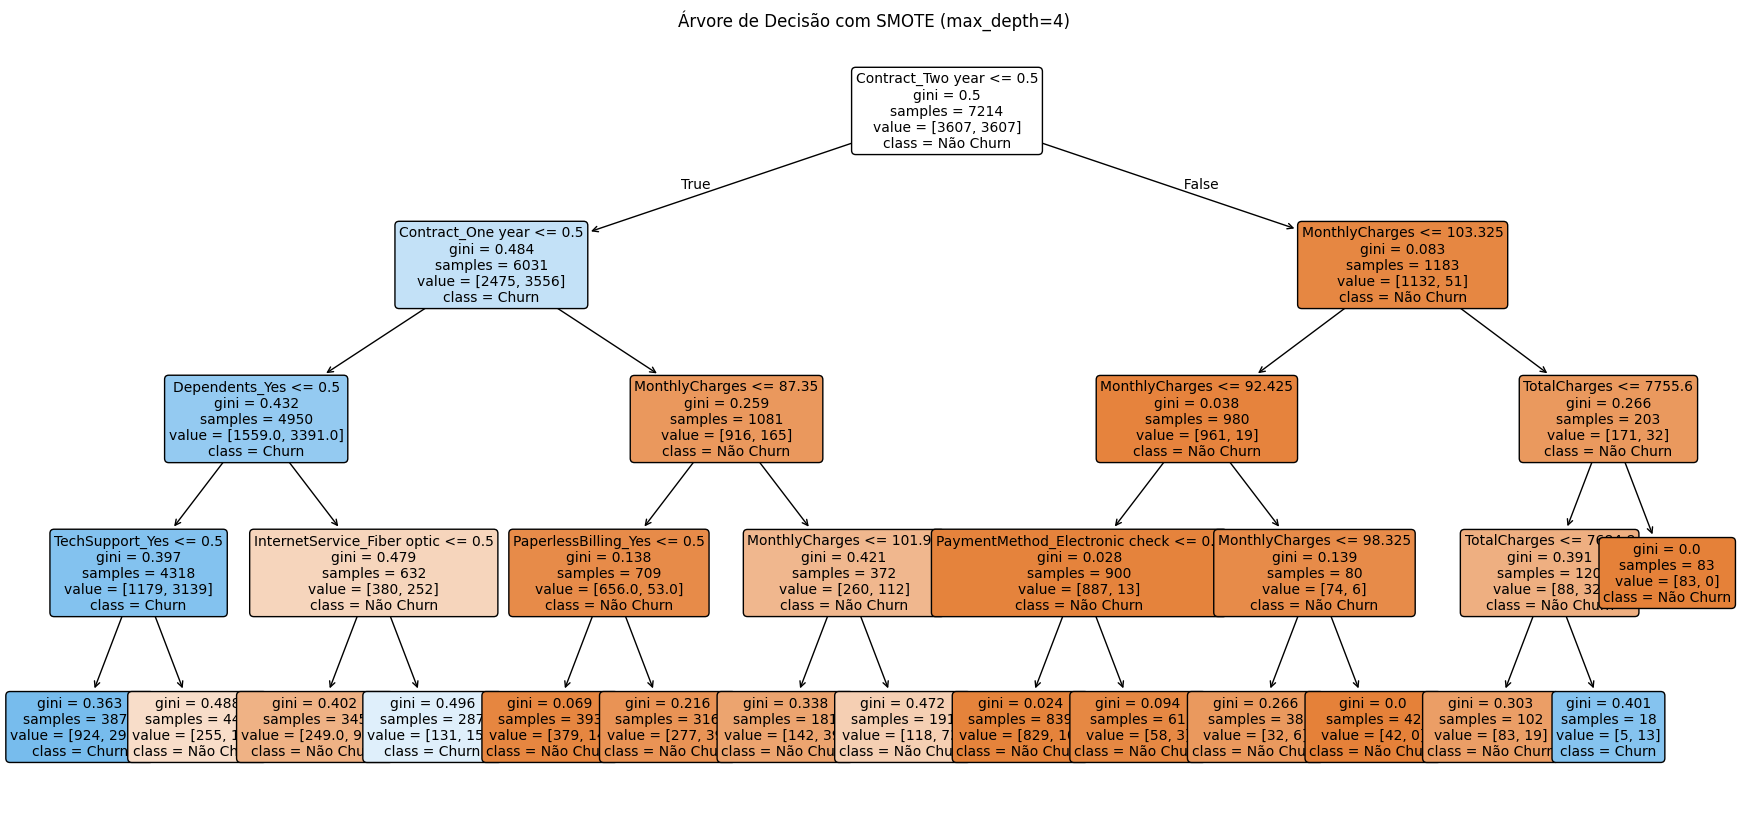

In [9]:
# ==============================================================================
# 8. MODELO 2: ÁRVORE DE DECISÃO
# ==============================================================================
arvore = DecisionTreeClassifier(max_depth=4, random_state=42)
arvore.fit(X_train_smote, y_train_smote)

y_pred_arvore = arvore.predict(X_test)

print("\n===== RESULTADOS - ÁRVORE DE DECISÃO (COM SMOTE) =====")
print(f"Acurácia: {accuracy_score(y_test, y_pred_arvore):.4f}\n")
print(classification_report(y_test, y_pred_arvore, target_names=["Não Churn", "Churn"]))

plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_arvore),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Não Churn", "Churn"],
    yticklabels=["Não Churn", "Churn"]
)
plt.title("Matriz de Confusão - Árvore de Decisão (SMOTE)")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.show()

# Desenho da Árvore
plt.figure(figsize=(22, 10))
plot_tree(
    arvore,
    feature_names=X.columns,
    class_names=["Não Churn", "Churn"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árvore de Decisão com SMOTE (max_depth=4)")
plt.show()